# Discriminative Project – Milestone 2: Object Detection

IE 7615 Deep Learning for AI  
Study Group 6: Bingyan Zhu, Muhan Li, Ruoxi Chen

This is our final notebook. We start from the best weights of the previous experiment and continue fine-tuning with more training photos and a low learning rate.


In [1]:
!pip install -q ultralytics==8.4.175
import torch
print('PyTorch:', torch.__version__)
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU: enable GPU in Colab')
from google.colab import drive
drive.mount('/content/drive')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 86.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 12.2 MB/s eta 0:00:00
PyTorch: 2.11.0+cu130
GPU: NVIDIA L4
Mounted at /content/drive


In [2]:
import os, json, random, time, uuid, hashlib, shutil, csv
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter, defaultdict, deque
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image, ImageOps, ImageEnhance, ImageDraw


V3_RUN_DIR = '/content/drive/MyDrive/IE7615_outputs_milestone2_v3/run_20261011_020943_UTC_991c9954'
V3_BEST_OVERRIDE = ''
SOURCE_DIR = '/content/drive/MyDrive/Colab Notebooks/IE 7615 深度学习/IE7615 Deep Learning for AI'
LOCAL_SRC = '/content/ie7615_src'

SOURCE_EXCLUSIONS = ''

SEED = 42
CANVAS, GRID_SIZES, GRID_MARGIN = 640, (2, 3), 8
TILE_SCALE, ROT_DEG = (0.90, 1.00), 5
N_TRAIN_IMAGES = 3000
EPOCHS, PATIENCE, BATCH = 30, 10, 16
LR = 3e-5
random.seed(SEED); np.random.seed(SEED)
assert N_TRAIN_IMAGES >= 100 and N_TRAIN_IMAGES % 2 == 0
assert 0 < TILE_SCALE[0] <= TILE_SCALE[1] <= 1 and 0 <= ROT_DEG <= 5
assert 2 * GRID_MARGIN < CANVAS // max(GRID_SIZES)
assert os.path.isdir('/content/drive/MyDrive'), 'Mount Drive first'

def sha256(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

candidates = [V3_BEST_OVERRIDE] if V3_BEST_OVERRIDE else [
    os.path.join(V3_RUN_DIR, 'model_best.pt'),
    os.path.join(V3_RUN_DIR, 'runs/yolov8_custom_v3/weights/best.pt'),
]
V3_BEST_PT = next((p for p in candidates if os.path.isfile(p)), None)
if V3_BEST_PT is None:
    raise FileNotFoundError('Best weights not found. Check V3_RUN_DIR or V3_BEST_OVERRIDE: ' + str(candidates))
V3_DATASET = os.path.join(V3_RUN_DIR, 'yolo_dataset')
reference_manifest = json.loads(Path(V3_DATASET, 'dataset_manifest.json').read_text())
ids = sorted({t['object_id'] for r in reference_manifest for t in r['tiles']})
assert len(ids) == 73, 'Expected 73 classes in the previous dataset'
id2idx = {o: i for i, o in enumerate(ids)}
idx2id = dict(enumerate(ids))
N_CLASSES = len(ids)
fixed_records = [r for r in reference_manifest if r['split'] in ('val', 'test')]
assert Counter(r['split'] for r in fixed_records) == {'val': 150, 'test': 150}
reference_hashes = {}
for r in fixed_records:
    name = r['image']
    assert Path(name).name == name and r['layout'] in ('2x2', '3x3')
    assert len(r['tiles']) == int(r['layout'][0]) ** 2
    for folder, filename in [('images', name), ('labels', Path(name).with_suffix('.txt').name)]:
        p = Path(V3_DATASET, folder, r['split'], filename)
        if not p.is_file():
            raise FileNotFoundError(f'Missing fixed evaluation file: {p}. Restore the previous dataset backup.')
        reference_hashes[str(p)] = sha256(p)
for split in ('val', 'test'):
    assert Counter(r['layout'] for r in fixed_records if r['split'] == split) == {'2x2': 75, '3x3': 75}
V3_WEIGHT_SHA256 = sha256(V3_BEST_PT)
RUN_ID = datetime.now(timezone.utc).strftime('run_%Y%m%d_%H%M%S_UTC_') + uuid.uuid4().hex[:8]
OUT_DIR = os.path.join('/content/drive/MyDrive/IE7615_outputs_milestone2_v4', RUN_ID)
LOCAL = os.path.join('/content/ms2_v4', RUN_ID)
DATASET = os.path.join(LOCAL, 'yolo_dataset')
PERSISTED_DATASET = os.path.join(OUT_DIR, 'yolo_dataset')
assert not Path(OUT_DIR).resolve().is_relative_to(Path(V3_RUN_DIR).resolve())
os.makedirs(OUT_DIR, exist_ok=False); os.makedirs(LOCAL, exist_ok=False)
print('Starting weights:', V3_BEST_PT)
print('Fixed validation/test data:', V3_DATASET)
print('Output folder:', OUT_DIR)


Starting weights: /content/drive/MyDrive/IE7615_outputs_milestone2_v3/run_20261011_020943_UTC_991c9954/runs/yolov8_custom_v3/weights/best.pt
Fixed validation/test data: /content/drive/MyDrive/IE7615_outputs_milestone2_v3/run_20261011_020943_UTC_991c9954/yolo_dataset
Output folder: /content/drive/MyDrive/IE7615_outputs_milestone2_v4/run_20261011_031048_UTC_edbdff91


## Source Cache

We copy the source photos to Colab and reuse the local cache.


In [3]:
EXTS = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')
cache_marker = Path(LOCAL_SRC, '.v4_source_cache.json')
cache = None
if cache_marker.is_file():
    candidate = json.loads(cache_marker.read_text())
    if candidate['source_dir'] == SOURCE_DIR and candidate['ids'] == ids:
        if all(Path(LOCAL_SRC, r['relative_path']).is_file()
               and Path(LOCAL_SRC, r['relative_path']).stat().st_size == r['bytes'] for r in candidate['files']):
            cache = candidate

if cache is None:
    if not os.path.isdir(SOURCE_DIR):
        raise FileNotFoundError('Source folder not found. Check SOURCE_DIR and the shared folder shortcut in MyDrive.')
    files = []
    t0 = time.time(); copied = 0
    for oid in ids:
        c = 'images_' + oid
        src_class, dst_class = Path(SOURCE_DIR, c), Path(LOCAL_SRC, c)
        if not src_class.is_dir():
            raise FileNotFoundError(f'Missing source class: {src_class}')
        dst_class.mkdir(parents=True, exist_ok=True)
        paths = sorted(p for p in src_class.iterdir() if p.is_file() and p.suffix.lower() in EXTS)
        assert paths, f'No source images for {oid}'
        for src in paths:
            dst = dst_class / src.name
            if not dst.is_file():
                shutil.copy2(src, dst); copied += 1
            elif dst.stat().st_size != src.stat().st_size:
                raise RuntimeError(f'File size mismatch: {dst}. Use a new LOCAL_SRC folder.')
            files.append({'object_id': oid, 'filename': src.name,
                          'relative_path': c + '/' + src.name, 'bytes': dst.stat().st_size})
    cache = {'source_dir': SOURCE_DIR, 'ids': ids, 'files': files}
    cache_marker.write_text(json.dumps(cache, ensure_ascii=False, indent=2))
    print(f'Cache ready: copied {copied} images in {time.time()-t0:.0f} s')
else:
    print('Using the local source cache.')
print('Cached photos:', len(cache['files']), 'Folder:', LOCAL_SRC)


Cache ready: copied 7343 images in 209 s
Cached photos: 7343 Folder: /content/ie7615_src


## Source Checks

We check bad images and duplicates, and leave out the fixed evaluation source photos. Background-only photos still need a manual check.


In [4]:
source_rows = []
source_lookup = {}
for r in cache['files']:
    item = dict(r)
    p = Path(LOCAL_SRC, r['relative_path'])
    item['sha256'] = sha256(p)
    try:
        with Image.open(p) as im:
            im.load()
            item.update(valid=True, width=im.width, height=im.height, error='')
    except Exception as e:
        item.update(valid=False, width=0, height=0, error=str(e))
    source_rows.append(item)
    source_lookup[(item['object_id'], item['filename'])] = item

holdout_hashes = set()
for r in fixed_records:
    for tile in r['tiles']:
        key = (tile['object_id'], tile['source_file'])
        if key not in source_lookup:
            raise FileNotFoundError(f'Evaluation source not found: {key}. Check the source dataset.')
        holdout_hashes.add(source_lookup[key]['sha256'])
hash_classes = defaultdict(set)
for r in source_rows:
    hash_classes[r['sha256']].add(r['object_id'])
conflict_hashes = {h for h, classes in hash_classes.items() if len(classes) > 1}
manual_hashes = set()
if SOURCE_EXCLUSIONS:
    with open(SOURCE_EXCLUSIONS, encoding='utf-8-sig', newline='') as f:
        for row in csv.DictReader(f):
            key = (row['object_id'].strip(), row['filename'].strip())
            if key not in source_lookup:
                raise ValueError(f'Exclusion entry not found: {key}')
            manual_hashes.add(source_lookup[key]['sha256'])

eligible_sources = {oid: [] for oid in ids}
seen_hashes = set()
for r in source_rows:
    h = r['sha256']
    reason = ('decode_error' if not r['valid'] else
              'manual_exclusion' if h in manual_hashes else
              'cross_class_duplicate' if h in conflict_hashes else
              'fixed_val_test_source' if h in holdout_hashes else
              'same_class_duplicate' if h in seen_hashes else '')
    r['exclude_from_new_train'] = reason
    if not reason:
        seen_hashes.add(h); eligible_sources[r['object_id']].append(r)
def write_csv(path, rows):
    with open(path, 'w', encoding='utf-8-sig', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader(); writer.writerows(rows)

review_indices = Counter()
for r in source_rows:
    review_indices[r['object_id']] += 1
    r['review_index'] = review_indices[r['object_id']]
write_csv(Path(OUT_DIR, 'source_index.csv'), source_rows)
Path(OUT_DIR, 'source_exclusions_template.csv').write_text('object_id,filename,reason\n', encoding='utf-8-sig')
assert all(eligible_sources.values()), ('No usable training photos for these classes. Check source_index.csv: '
                                      + str([oid for oid in ids if not eligible_sources[oid]]))
review_dir = Path(OUT_DIR, 'source_review'); review_dir.mkdir(exist_ok=False)
for oid in ids:
    rows = [r for r in source_rows if r['object_id'] == oid]
    for start in range(0, len(rows), 100):
        page = rows[start:start + 100]
        sheet = Image.new('RGB', (1000, ((len(page)+9)//10)*115), 'white')
        draw = ImageDraw.Draw(sheet)
        for j, r in enumerate(page):
            x, y = (j % 10) * 100, (j // 10) * 115
            if r['valid']:
                with Image.open(Path(LOCAL_SRC, r['relative_path'])) as im:
                    thumb = ImageOps.contain(im.convert('RGB'), (94, 90))
                sheet.paste(thumb, (x+(100-thumb.width)//2, y))

            draw.text((x+3, y+92), f'{oid} #{r["review_index"]}',
                      fill='red' if r['exclude_from_new_train'] else 'black')
        sheet.save(review_dir / f'{oid}_{start//100+1:02d}.jpg', quality=90)
quality_counts = dict(Counter(r['exclude_from_new_train'] or 'eligible' for r in source_rows))
print('Source checks:', quality_counts)
print('Usable training photos:', sum(map(len, eligible_sources.values())))
print('Review thumbnails:', review_dir)


Source checks: {'eligible': 5614, 'fixed_val_test_source': 1710, 'same_class_duplicate': 19}
Usable training photos: 5614
Review thumbnails: /content/drive/MyDrive/IE7615_outputs_milestone2_v4/run_20261011_031048_UTC_edbdff91/source_review


## Grid Images

We make 3,000 training images, half 2×2 and half 3×3. Photos stay inside their cells with no overlap.


In [5]:
source_queues = {oid: deque() for oid in ids}
source_usage = Counter()
def next_source(oid):
    if not source_queues[oid]:
        items = list(eligible_sources[oid]); random.shuffle(items)
        source_queues[oid].extend(items)
    r = source_queues[oid].popleft()
    source_usage[(oid, r['filename'])] += 1
    return r

layout_plan = [g for g in GRID_SIZES for _ in range(N_TRAIN_IMAGES // 2)]
random.shuffle(layout_plan)
n_train_boxes = sum(g*g for g in layout_plan)
schedule = [ids[i % N_CLASSES] for i in range(n_train_boxes)]
random.shuffle(schedule)
class_schedule = iter(schedule)
def make_multi_image(out_img, out_lbl, grid_size):
    bg_color = tuple(random.randint(150, 255) for _ in range(3))
    bg = Image.new('RGB', (CANVAS, CANVAS), bg_color)
    edges = [round(i * CANVAS / grid_size) for i in range(grid_size + 1)]
    picked = [next(class_schedule) for _ in range(grid_size ** 2)]
    labels, tiles = [], []
    for cell_index, c in enumerate(picked):
        row, col = divmod(cell_index, grid_size)
        left, right = edges[col], edges[col + 1]
        top, bottom = edges[row], edges[row + 1]
        inner_w = right - left - 2 * GRID_MARGIN
        inner_h = bottom - top - 2 * GRID_MARGIN
        record = next_source(c)
        source_path = str(Path(LOCAL_SRC, record['relative_path']))
        with Image.open(source_path) as source:
            im = source.convert('RGB')

        im = im.resize((inner_w, inner_w), Image.Resampling.LANCZOS)
        if random.random() < 0.5:
            im = ImageOps.mirror(im)
        im = ImageEnhance.Brightness(im).enhance(random.uniform(0.7, 1.3))
        im = ImageEnhance.Contrast(im).enhance(random.uniform(0.7, 1.3))
        angle = random.uniform(-ROT_DEG, ROT_DEG)
        im = im.rotate(angle, expand=True, resample=Image.Resampling.BICUBIC, fillcolor=bg_color)
        fill = random.uniform(*TILE_SCALE)
        scale = min(inner_w / im.width, inner_h / im.height) * fill
        w, h = max(1, int(im.width * scale)), max(1, int(im.height * scale))
        im = im.resize((w, h), Image.Resampling.LANCZOS)
        x = left + (right - left - w) // 2
        y = top + (bottom - top - h) // 2
        assert left + GRID_MARGIN <= x and x + w <= right - GRID_MARGIN
        assert top + GRID_MARGIN <= y and y + h <= bottom - GRID_MARGIN
        bg.paste(im, (x, y))
        oid = c
        labels.append((id2idx[oid], (x + w / 2) / CANVAS, (y + h / 2) / CANVAS,
                       w / CANVAS, h / CANVAS))
        tiles.append({'object_id': oid, 'source_class': 'images_' + c, 'source_sha256': record['sha256'], 'source_file': os.path.basename(source_path),
                      'row': row, 'col': col, 'rotation_deg': angle, 'bbox_xyxy': [x, y, x + w, y + h]})
    bg.save(out_img, quality=95)
    with open(out_lbl, 'w') as f:
        for cl, xc, yc, bw, bh in labels:
            f.write(f'{cl} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}\n')
    return labels, tiles


all_img_dir = os.path.join(DATASET, 'images', 'train')
all_lbl_dir = os.path.join(DATASET, 'labels', 'train')
os.makedirs(all_img_dir, exist_ok=False); os.makedirs(all_lbl_dir, exist_ok=False)
image_layout, split_map, dataset_manifest = {}, {}, []
per_class_count = {oid: 0 for oid in ids}
t0 = time.time()
for i, g in enumerate(layout_plan):
    name = f'train_v4_{i:05d}.jpg'
    labels, tiles = make_multi_image(os.path.join(all_img_dir, name),
                                    os.path.join(all_lbl_dir, Path(name).with_suffix('.txt').name), g)
    image_layout[name] = f'{g}x{g}'; split_map[name] = 'train'
    dataset_manifest.append({'image': name, 'layout': image_layout[name], 'split': 'train', 'tiles': tiles})
    for cl, *_ in labels:
        per_class_count[idx2id[cl]] += 1
    if (i+1) % 100 == 0:
        print(f'Training images: {i+1}/{N_TRAIN_IMAGES}')
assert max(per_class_count.values()) - min(per_class_count.values()) <= 1
coverage_rows = []
for oid in ids:
    available = len(eligible_sources[oid])
    used = sum(source_usage[(oid, r['filename'])] > 0 for r in eligible_sources[oid])
    coverage_rows.append({'object_id': oid, 'available_unique_photos': available,
                          'used_unique_photos': used, 'coverage_fraction': round(used/available, 4),
                          'train_boxes': per_class_count[oid]})
write_csv(Path(OUT_DIR, 'source_coverage.csv'), coverage_rows)
usage_rows = [{'object_id': oid, 'filename': name, 'train_uses': count}
              for (oid, name), count in sorted(source_usage.items())]
write_csv(Path(OUT_DIR, 'source_usage.csv'), usage_rows)
print(f'Done in {time.time()-t0:.0f} s; training boxes: {n_train_boxes}')
print('Boxes per class:', min(per_class_count.values()), 'to', max(per_class_count.values()))
print('Unique photos used:', sum(r['used_unique_photos'] for r in coverage_rows))

Training images: 100/3000
Training images: 200/3000
Training images: 300/3000
Training images: 400/3000
Training images: 500/3000
Training images: 600/3000
Training images: 700/3000
Training images: 800/3000
Training images: 900/3000
Training images: 1000/3000
Training images: 1100/3000
Training images: 1200/3000
Training images: 1300/3000
Training images: 1400/3000
Training images: 1500/3000
Training images: 1600/3000
Training images: 1700/3000
Training images: 1800/3000
Training images: 1900/3000
Training images: 2000/3000
Training images: 2100/3000
Training images: 2200/3000
Training images: 2300/3000
Training images: 2400/3000
Training images: 2500/3000
Training images: 2600/3000
Training images: 2700/3000
Training images: 2800/3000
Training images: 2900/3000
Training images: 3000/3000
Done in 214 s; training boxes: 19500
Boxes per class: 267 to 268
Unique photos used: 5614


## Samples

Green boxes show the labels around each pasted photo.


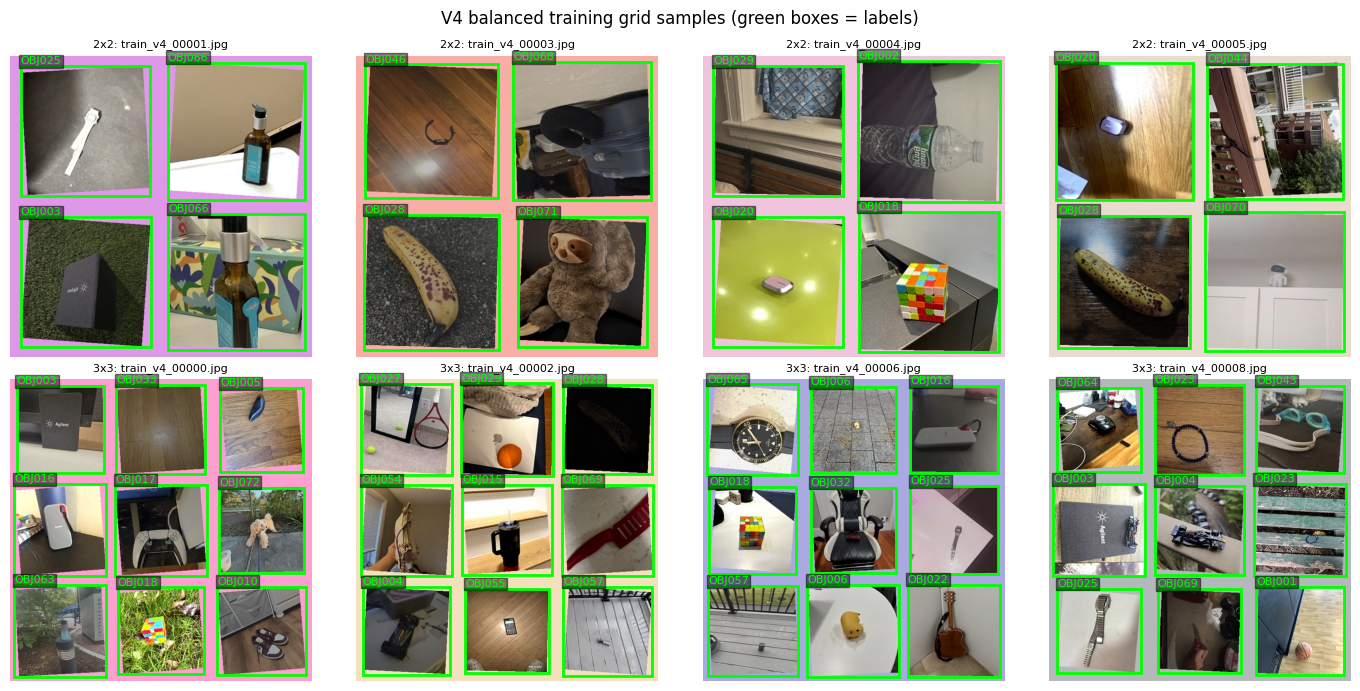

In [6]:
def draw_yolo(ax, img_path, lbl_path, title=''):
    im = Image.open(img_path)
    W, H = im.size
    ax.imshow(im)
    with open(lbl_path) as f:
        for line in f:
            cl, xc, yc, bw, bh = line.split()
            cl = int(cl)
            x = (float(xc) - float(bw) / 2) * W
            y = (float(yc) - float(bh) / 2) * H
            ax.add_patch(patches.Rectangle((x, y), float(bw) * W, float(bh) * H,
                                           fill=False, edgecolor='lime', linewidth=2))
            ax.text(x, y - 4, idx2id[cl], color='lime', fontsize=8,
                    bbox=dict(facecolor='black', alpha=0.5, pad=1))
    ax.set_title(title, fontsize=8)
    ax.axis('off')


fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for row, g in enumerate(GRID_SIZES):
    sample_names = sorted(n for n, layout in image_layout.items() if layout == f'{g}x{g}')[:4]
    for ax, name in zip(axes[row], sample_names):
        draw_yolo(ax, os.path.join(all_img_dir, name),
                  os.path.join(all_lbl_dir, name.replace('.jpg', '.txt')), f'{g}x{g}: {name}')
plt.suptitle('V4 balanced training grid samples (green boxes = labels)')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'concat_samples.png'), dpi=120)
plt.show()

## Data Split

We keep the same 150 validation images and 150 test images from the previous experiment.


In [7]:
for split in ('val', 'test'):
    os.makedirs(os.path.join(DATASET, 'images', split), exist_ok=False)
    os.makedirs(os.path.join(DATASET, 'labels', split), exist_ok=False)
for r in fixed_records:
    name, split = r['image'], r['split']
    assert name not in split_map
    for folder, filename in [('images', name), ('labels', Path(name).with_suffix('.txt').name)]:
        old = Path(V3_DATASET, folder, split, filename)
        new = Path(DATASET, folder, split, filename)
        shutil.copy2(old, new)
        assert sha256(new) == reference_hashes[str(old)], 'Fixed evaluation file copy mismatch'
    lines = Path(DATASET, 'labels', split, Path(name).with_suffix('.txt').name).read_text().splitlines()
    assert len(lines) == len(r['tiles'])
    for line in lines:
        cl, xc, yc, w, h = map(float, line.split())
        assert cl == int(cl) and 0 <= cl < N_CLASSES
        assert 0 < w <= 1 and 0 < h <= 1
        assert -1e-6 <= xc-w/2 and xc+w/2 <= 1+1e-6
        assert -1e-6 <= yc-h/2 and yc+h/2 <= 1+1e-6
    image_layout[name] = r['layout']; split_map[name] = split
    dataset_manifest.append(r)
cnt = dict(Counter(split_map.values()))
assert cnt == {'train': N_TRAIN_IMAGES, 'val': 150, 'test': 150}
Path(DATASET, 'dataset_manifest.json').write_text(json.dumps(dataset_manifest, ensure_ascii=False, indent=2))
def write_dataset_yamls(root):
    def write_one(name, test_entry):
        with open(os.path.join(root, name), 'w') as f:
            f.write(f'path: {json.dumps(root)}\ntrain: images/train\nval: images/val\ntest: {test_entry}\n')
            f.write(f'nc: {N_CLASSES}\nnames:\n')
            for oid in ids:
                f.write(f'  - {oid}\n')
    write_one('data.yaml', 'images/test')
    for g in GRID_SIZES:
        list_name = f'test_{g}x{g}.txt'
        test_names = sorted(n for n in split_map if split_map[n] == 'test' and image_layout[n] == f'{g}x{g}')
        with open(os.path.join(root, list_name), 'w') as f:
            f.writelines(f'./images/test/{n}\n' for n in test_names)
        write_one(f'data_{g}x{g}.yaml', list_name)


write_dataset_yamls(DATASET)
YAML_PATH = os.path.join(DATASET, 'data.yaml')
shutil.copytree(DATASET, PERSISTED_DATASET, dirs_exist_ok=False)
write_dataset_yamls(PERSISTED_DATASET)
print('Image counts:', cnt)
print('Local training YAML:', YAML_PATH)
print('Dataset backup:', PERSISTED_DATASET)

Image counts: {'train': 3000, 'val': 150, 'test': 150}
Local training YAML: /content/ms2_v4/run_20261011_031048_UTC_edbdff91/yolo_dataset/data.yaml
Dataset backup: /content/drive/MyDrive/IE7615_outputs_milestone2_v4/run_20261011_031048_UTC_edbdff91/yolo_dataset


## Fine Tuning

We start from the previous best weights. We use AdamW with a learning rate of 3e-5.


In [8]:
from ultralytics import YOLO
baseline = YOLO(V3_BEST_PT)
assert [baseline.names[i] for i in range(len(baseline.names))] == ids, 'Starting weights have a different class order'
model = YOLO(V3_BEST_PT)
t0 = time.time()
train_res = model.train(
    data=YAML_PATH, epochs=EPOCHS, imgsz=CANVAS, batch=BATCH, patience=PATIENCE,
    project=os.path.join(OUT_DIR, 'runs'), name='yolov8_custom_v4', seed=SEED,
    resume=False, optimizer='AdamW', lr0=LR, lrf=0.1, cos_lr=True,
    momentum=0.9, weight_decay=0.0005, warmup_epochs=1.0, warmup_bias_lr=LR,
    mosaic=0.0, translate=0.0, scale=0.0,
)
RUN_DIR = str(train_res.save_dir if hasattr(train_res, 'save_dir') else model.trainer.save_dir)
BEST_PT = os.path.join(RUN_DIR, 'weights', 'best.pt')
assert Path(BEST_PT).is_file() and Path(BEST_PT).resolve().is_relative_to(Path(OUT_DIR).resolve())
assert sha256(V3_BEST_PT) == V3_WEIGHT_SHA256
print(f'Fine-tuning done in {(time.time()-t0)/60:.1f} min')
print('Candidate best weights:', BEST_PT)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/ms2_v4/run_20261011_031048_UTC_edbdff91/yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flip

## Evaluation

We select the model using validation mAP@0.5:0.95, then test both models on the same images.


In [9]:
import pandas as pd
candidate = YOLO(BEST_PT)
EVAL_DIR = os.path.join(OUT_DIR, 'evaluations')
def evaluate(detector, tag, split='test', yaml_path=YAML_PATH):
    return detector.val(data=yaml_path, split=split, imgsz=CANVAS, batch=BATCH,
                        verbose=False, project=EVAL_DIR, name=tag, plots=True, exist_ok=False)

v3_val_metrics = evaluate(baseline, 'v3_fixed_val', 'val')
v4_val_metrics = evaluate(candidate, 'v4_fixed_val', 'val')
def choose_model(v3_map, v4_map):
    assert np.isfinite(v3_map) and np.isfinite(v4_map), 'Invalid validation scores'
    return 'V4' if v4_map > v3_map else 'V3'
SELECTED_VERSION = choose_model(float(v3_val_metrics.box.map), float(v4_val_metrics.box.map))
SELECTED_PT = BEST_PT if SELECTED_VERSION == 'V4' else V3_BEST_PT
best = candidate if SELECTED_VERSION == 'V4' else baseline
selection = {'criterion': 'validation mAP@0.5:0.95; ties keep V3',
             'v3_val_map': float(v3_val_metrics.box.map), 'v4_val_map': float(v4_val_metrics.box.map),
             'selected_version': SELECTED_VERSION, 'selected_weight': SELECTED_PT,
             'test_used_for_selection': False}
Path(OUT_DIR, 'model_selection.json').write_text(json.dumps(selection, indent=2))
print('Selected by validation:', SELECTED_VERSION, '; starting test evaluation.')

v3_test_metrics = evaluate(baseline, 'v3_fixed_test')
v4_test_metrics = evaluate(candidate, 'v4_fixed_test')
layout_metrics_all = {}
for version, detector in [('V3', baseline), ('V4', candidate)]:
    for g in GRID_SIZES:
        layout = f'{g}x{g}'
        layout_metrics_all[(version, layout)] = evaluate(detector, f'{version.lower()}_fixed_test_{layout}',
                                     yaml_path=os.path.join(DATASET, f'data_{layout}.yaml'))

def metric_row(version, split, m):
    return {'model': version, 'split': split, 'P': round(m.box.mp, 4), 'R': round(m.box.mr, 4),
            'mAP@0.5': round(m.box.map50, 4), 'mAP@0.5:0.95': round(m.box.map, 4)}
summary = pd.DataFrame([
    metric_row('V3', 'val', v3_val_metrics), metric_row('V3', 'test', v3_test_metrics),
    metric_row('V4', 'val', v4_val_metrics), metric_row('V4', 'test', v4_test_metrics),
])
layout_summary = pd.DataFrame([metric_row(v, layout, m) for (v, layout), m in layout_metrics_all.items()])
summary.to_csv(os.path.join(OUT_DIR, 'detection_metrics.csv'), index=False)
layout_summary.to_csv(os.path.join(OUT_DIR, 'detection_metrics_by_layout.csv'), index=False)
print(summary.to_string(index=False)); print(layout_summary.to_string(index=False))
test_metrics = v4_test_metrics if SELECTED_VERSION == 'V4' else v3_test_metrics
ap_rows = [{'object_id': idx2id[int(cl)], 'AP@0.5': float(ap), 'model': SELECTED_VERSION}
           for cl, ap in zip(test_metrics.box.ap_class_index, test_metrics.box.ap50)]
pd.DataFrame(ap_rows).to_csv(os.path.join(OUT_DIR, 'per_class_ap_test.csv'), index=False)
print('Evaluation plots:', EVAL_DIR)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 73 layers, 3,150,203 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2742.8±915.2 MB/s, size: 130.6 KB)
val: Scanning /content/ms2_v4/run_20261011_031048_UTC_edbdff91/yolo_dataset/labels/val.cache... 150 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 150/150 52.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 4.0it/s 2.5s
                   all        150        975      0.919      0.877      0.925      0.916
Speed: 1.4ms preprocess, 3.2ms inference, 0.0ms loss, 5.1ms postprocess per image
Results saved to /content/drive/MyDrive/IE7615_outputs_milestone2_v4/run_20261011_031048_UTC_edbdff91/evaluations/v3_fixed_val
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 73 layers, 3,150,203 parameters, 0 gradien

## Demo

We show four test images for each layout, with predicted IDs, boxes, and confidence scores.


== multi_0006.jpg (2x2, labels: 4, predictions: 3) ==
   OBJ054  bbox=[16.1, 15.9, 303.4, 303.2]  conf=0.999
   OBJ048  bbox=[11.6, 332.2, 308.1, 628.1]  conf=0.999
   OBJ065  bbox=[328.6, 8.5, 630.8, 310.7]  conf=0.985
== multi_0025.jpg (2x2, labels: 4, predictions: 4) ==
   OBJ013  bbox=[16.3, 16.1, 303.8, 303.7]  conf=1.000
   OBJ066  bbox=[22.3, 342.2, 297.5, 617.1]  conf=1.000
   OBJ061  bbox=[329.4, 329.7, 629.8, 630.3]  conf=0.999
   OBJ063  bbox=[338.2, 18.1, 620.9, 301.1]  conf=0.984
== multi_0035.jpg (2x2, labels: 4, predictions: 5) ==
   OBJ047  bbox=[18.0, 16.5, 300.9, 299.9]  conf=0.991
   OBJ032  bbox=[340.3, 20.0, 619.1, 299.1]  conf=0.911
   OBJ038  bbox=[9.6, 329.0, 311.3, 630.8]  conf=0.860
   OBJ003  bbox=[9.3, 329.0, 310.8, 630.6]  conf=0.845
   OBJ004  bbox=[329.8, 330.5, 629.6, 629.3]  conf=0.550
== multi_0046.jpg (2x2, labels: 4, predictions: 5) ==
   OBJ004  bbox=[342.0, 342.3, 617.8, 617.0]  conf=0.998
   OBJ029  bbox=[18.0, 338.1, 302.1, 621.9]  conf=0.982
   

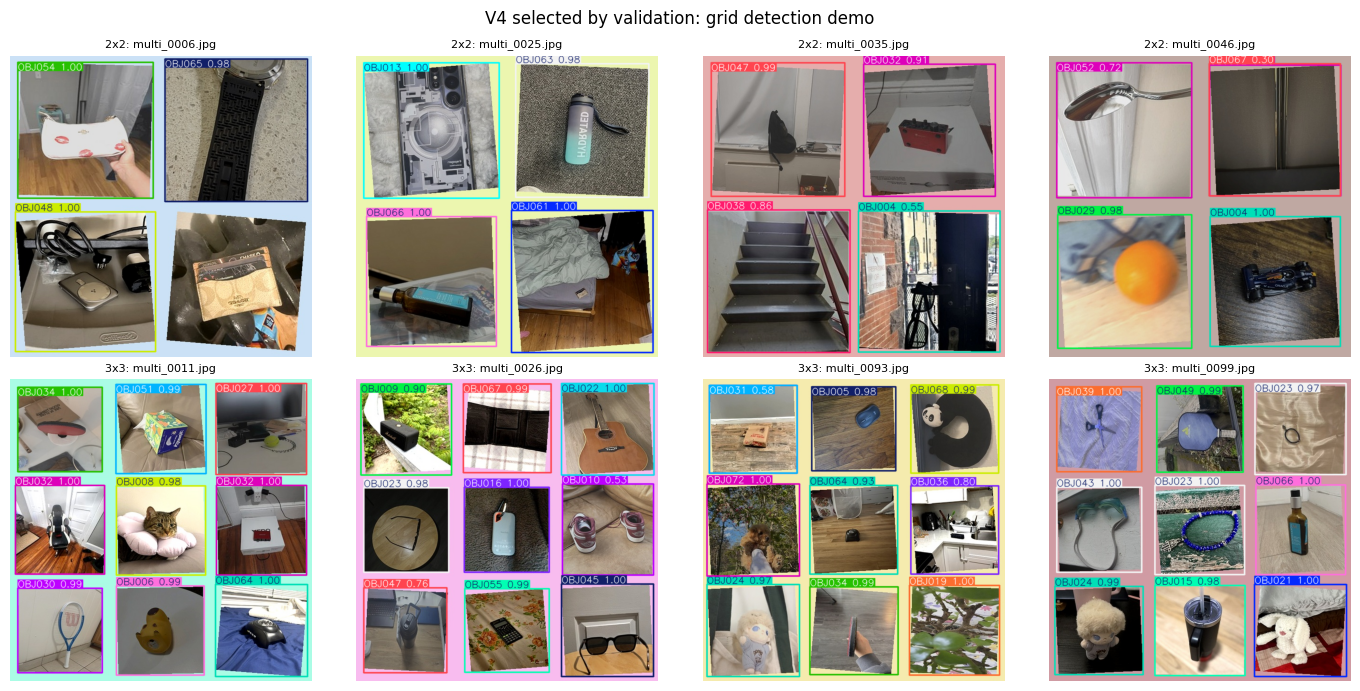

In [10]:
test_imgs = []
for g in GRID_SIZES:
    test_imgs.extend(sorted(n for n in split_map if split_map[n] == 'test' and image_layout[n] == f'{g}x{g}')[:4])
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
demo_records = []
for ax, name in zip(axes.flat, test_imgs):
    path = os.path.join(DATASET, 'images', 'test', name)
    r = best.predict(path, imgsz=CANVAS, conf=0.25, verbose=False)[0]
    g = int(image_layout[name][0])
    print(f'== {name} ({g}x{g}, labels: {g*g}, predictions: {len(r.boxes)}) ==')
    predictions = []
    for b in r.boxes:
        bbox = [round(v, 1) for v in b.xyxy[0].tolist()]
        oid, confidence = r.names[int(b.cls)], round(float(b.conf), 3)
        predictions.append({'object_id': oid, 'bbox_xyxy': bbox, 'confidence': confidence})
        print(f'   {oid}  bbox={bbox}  conf={confidence:.3f}')
    demo_records.append({'image': name, 'layout': image_layout[name], 'predictions': predictions})
    ax.imshow(r.plot()[..., ::-1])
    ax.set_title(f'{g}x{g}: {name}', fontsize=8); ax.axis('off')
plt.suptitle(f'{SELECTED_VERSION} selected by validation: grid detection demo')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'detection_demo.png'), dpi=120)
plt.show()
with open(os.path.join(OUT_DIR, 'demo_predictions.json'), 'w') as f:
    json.dump(demo_records, f, ensure_ascii=False, indent=2)

## Save Model

We save the selected model and run settings.


In [11]:
MODEL_EXPORT = os.path.join(OUT_DIR, 'model_selected.pt')
shutil.copy2(SELECTED_PT, MODEL_EXPORT)
shutil.copy2(BEST_PT, os.path.join(OUT_DIR, 'v4_candidate_best.pt'))
assert sha256(V3_BEST_PT) == V3_WEIGHT_SHA256, 'Starting weights were changed'
assert all(sha256(path) == expected for path, expected in reference_hashes.items()), 'Fixed evaluation files were changed'
run_info = {
    'version': 'V4', 'run_id': RUN_ID, 'seed': SEED, 'canvas': CANVAS,
    'grid_sizes': list(GRID_SIZES), 'grid_margin': GRID_MARGIN, 'rotation_deg': ROT_DEG,
    'tile_scale': list(TILE_SCALE), 'split_images': cnt, 'train_boxes': n_train_boxes,
    'epochs_max': EPOCHS, 'patience': PATIENCE, 'batch': BATCH,
    'optimizer': 'AdamW', 'lr0': LR, 'lrf': 0.1, 'cos_lr': True,
    'warmup_epochs': 1.0, 'warmup_bias_lr': LR, 'weight_decay': 0.0005, 'momentum': 0.9,
    'mosaic': 0.0, 'translate': 0.0, 'scale': 0.0,
    'v3_best_pt': V3_BEST_PT, 'v3_weight_sha256': V3_WEIGHT_SHA256,
    'v4_candidate_best_pt': BEST_PT, 'model_selection': selection,
    'fixed_eval_v3_run': V3_RUN_DIR, 'fixed_eval_hashes': reference_hashes,
    'source_dir': SOURCE_DIR, 'local_source_cache': LOCAL_SRC,
    'source_exclusions': SOURCE_EXCLUSIONS, 'source_quality_counts': quality_counts,
    'new_train_excludes_fixed_eval_source_hashes': True,
    'source_coverage': coverage_rows, 'dataset': PERSISTED_DATASET,
    'metrics': summary.to_dict(orient='records'), 'layout_metrics': layout_summary.to_dict(orient='records'),
    'ultralytics_version': __import__('ultralytics').__version__,
    'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU',
}
Path(OUT_DIR, 'run_info.json').write_text(json.dumps(run_info, ensure_ascii=False, indent=2))
print('Starting weights and evaluation files verified.')
print('All outputs:', OUT_DIR)
print('Selected model:', MODEL_EXPORT, 'Version:', SELECTED_VERSION)
print('Candidate model:', os.path.join(OUT_DIR, 'v4_candidate_best.pt'))

Starting weights and evaluation files verified.
All outputs: /content/drive/MyDrive/IE7615_outputs_milestone2_v4/run_20261011_031048_UTC_edbdff91
Selected model: /content/drive/MyDrive/IE7615_outputs_milestone2_v4/run_20261011_031048_UTC_edbdff91/model_selected.pt Version: V4
Candidate model: /content/drive/MyDrive/IE7615_outputs_milestone2_v4/run_20261011_031048_UTC_edbdff91/v4_candidate_best.pt


## Inference Script

The script returns object IDs, box coordinates, and confidence scores.


In [12]:
PY = r'''
import sys, json
from pathlib import Path
from ultralytics import YOLO

BEST_PT = Path(__file__).resolve().parent / 'model_selected.pt'
model = YOLO(str(BEST_PT))

def detect(path, conf=0.25):
    r = model.predict(path, imgsz=640, conf=conf, verbose=False)[0]
    return [{'object_id': r.names[int(b.cls)],
             'bbox_xyxy': [round(v, 1) for v in b.xyxy[0].tolist()],
             'confidence': round(float(b.conf), 3)} for b in r.boxes]

if __name__ == '__main__':
    for p in sys.argv[1:]:
        print(p)
        print(json.dumps(detect(p), ensure_ascii=False, indent=2))
'''
with open(os.path.join(OUT_DIR, 'predict.py'), 'w') as f:
    f.write(PY)
with open(os.path.join(OUT_DIR, 'requirements_inference.txt'), 'w') as f:
    f.write('ultralytics==8.4.175\n')
print('Saved:', os.path.join(OUT_DIR, 'predict.py'))
print('Usage: python predict.py <image_path> [more_images...]')

Saved: /content/drive/MyDrive/IE7615_outputs_milestone2_v4/run_20261011_031048_UTC_edbdff91/predict.py
Usage: python predict.py <image_path> [more_images...]
